# Results analytics

In [3]:
import pandas as pd
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
import statsmodels.api as sm

data = pd.read_csv("experiment_results/data/final_results.csv")

C:\Users\nande\AppData\Local\Temp\ipykernel_27384\2231583060.py:9: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("experiment_results/data/final_results.csv")


In [4]:
df = data.pivot_table(index = "initial_budget", columns = ["experiment", "decision"], values ="budget",aggfunc='count')

In [148]:
import pandas as pd
import scipy.stats as stats

def perform_statistical_tests(df):
    # Flatten the multi-level column structure for easier processing
    df.columns = ['_'.join(map(str, col)).strip() for col in df.columns.values]

    # Initialize a dictionary to store test results
    results = {}

    # Independent Samples t-test and Mann-Whitney U Test between dqn and random for each decision
    for decision in [0, 1]:
        dqn_col = f'dqn_{decision}'
        random_col = f'random_{decision}'

        # T-test
        t_stat, t_p = stats.ttest_ind(df[dqn_col], df[random_col], equal_var=False)
        results[f'T-test Decision {decision}'] = t_p

        # Mann-Whitney U Test
        u_stat, u_p = stats.mannwhitneyu(df[dqn_col], df[random_col])
        results[f'Mann-Whitney U Test Decision {decision}'] = u_p

    # Chi-Square Test of Independence
    for budget in df.index:
        obs = df.loc[budget, [f'dqn_{i}' for i in [0, 1]] + [f'random_{i}' for i in [0, 1]]].values.reshape(2, 2)
        chi2, chi_p, _, _ = stats.chi2_contingency(obs)
        results[f'Chi-Square Test Budget {budget}'] = chi_p

    # Fisher's Exact Test
    for budget in df.index:
        obs = df.loc[budget, [f'dqn_{i}' for i in [0, 1]] + [f'random_{i}' for i in [0, 1]]].values.reshape(2, 2)
        _, fisher_p = stats.fisher_exact(obs)
        results[f'Fisher Exact Test Budget {budget}'] = fisher_p

    return pd.DataFrame.from_dict(results, orient='index', columns=['P-Value'])

# Example usage:
# df = pd.DataFrame(...)  # Your pivot table data
# test_results = perform_statistical_tests(df)
# print(test_results)


In [149]:
df

experiment       dqn       random      
decision           0     1      0     1
initial_budget                         
1000000         5201  4756    183   199
5000000         5099  4825    960   957
10000000        4836  4860   1971  1920
15000000        4865  4763   2957  2884

In [150]:
test_results = perform_statistical_tests(df)
print(test_results)

                                    P-Value
T-test Decision 0                  0.009481
Mann-Whitney U Test Decision 0     0.028571
T-test Decision 1                  0.010739
Mann-Whitney U Test Decision 1     0.028571
Chi-Square Test Budget 1000000     0.107436
Chi-Square Test Budget 5000000     0.308066
Chi-Square Test Budget 10000000    0.422477
Chi-Square Test Budget 15000000    0.921767
Fisher Exact Test Budget 1000000   0.105637
Fisher Exact Test Budget 5000000   0.306236
Fisher Exact Test Budget 10000000  0.414532
Fisher Exact Test Budget 15000000  0.920728


In [151]:
df = data.query("episodes<10").pivot_table(index = ["initial_budget"], columns = ["experiment"],
                                 values = "steps", aggfunc =["max", "mean", "std","count"])

In [152]:
data['new_cum_sum'] = data.pivot_table(index = "initial_budget", columns = ["experiment", "episodes"], values ="rewards",aggfunc='cumsum')

<Axes: xlabel='episodes'>

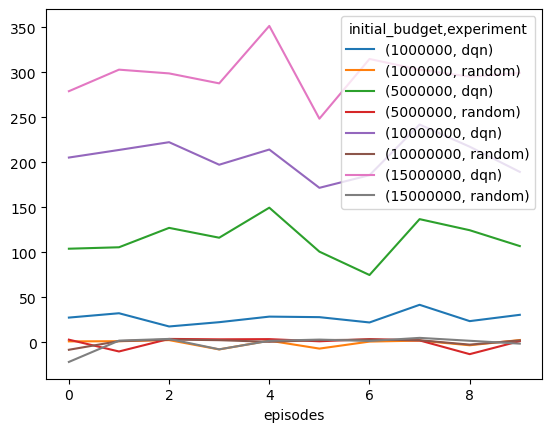

In [159]:
data.query("episodes<10").pivot_table(index = ["initial_budget", "experiment"], columns = [ "episodes"], values ="new_cum_sum",aggfunc='last').T.plot()

Average Steps per Episode: experiment  initial_budget
dqn         1000000            44.5
            5000000           197.2
            10000000          375.0
            15000000          585.1
random      1000000            38.2
            5000000           191.7
            10000000          389.1
            15000000          584.1
dtype: float64


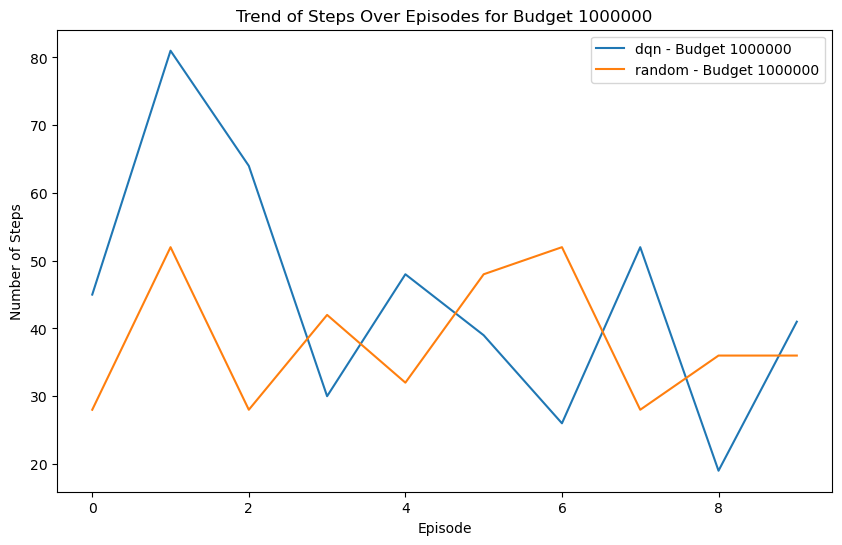

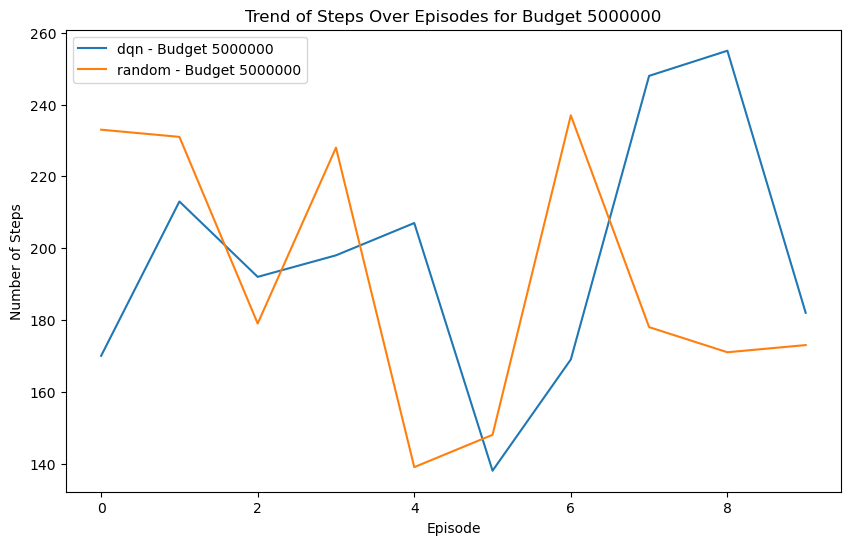

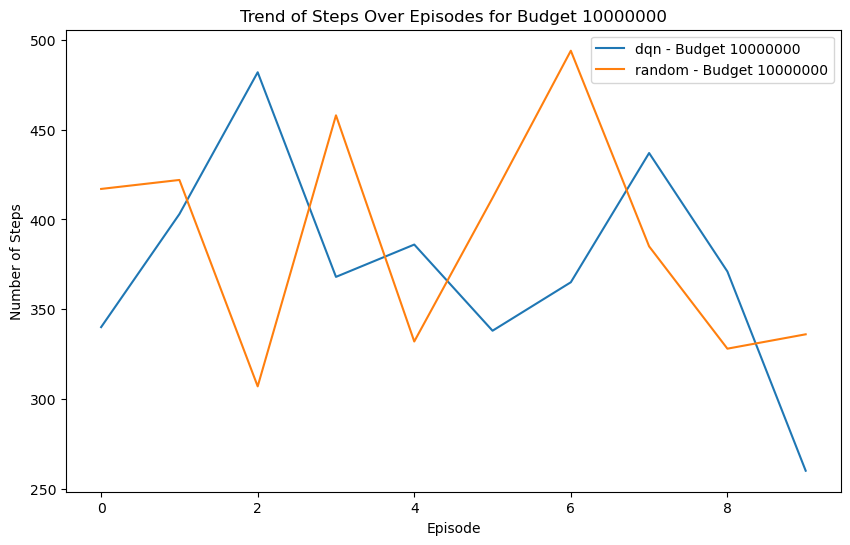

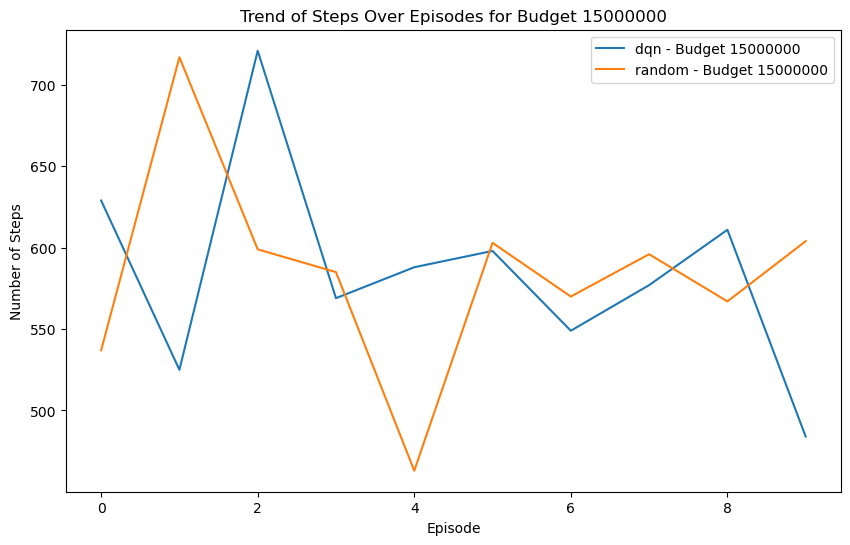

ANOVA Table:
                      sum_sq    df           F        PR(>F)
C(Experiment)  2.112500e+00   1.0    0.000938  9.756529e-01
C(Budget)      3.315370e+06   3.0  490.523084  3.521391e-49
Residual       1.689711e+05  75.0         NaN           NaN
Mann-Whitney U Test for Budget 1000000: p-value = 0.5438313160227017
Mann-Whitney U Test for Budget 5000000: p-value = 0.7913367801006604
Mann-Whitney U Test for Budget 10000000: p-value = 0.8501067391385259
Mann-Whitney U Test for Budget 15000000: p-value = 1.0
Descriptive Statistics:
 experiment            dqn                                         random  \
initial_budget   1000000     5000000     10000000    15000000   1000000    
count           10.000000   10.000000   10.000000   10.000000  10.000000   
mean            44.500000  197.200000  375.000000  585.100000  38.200000   
std             18.337878   35.847827   59.797807   63.860003   9.727395   
min             19.000000  138.000000  260.000000  484.000000  28.000000   
25

In [80]:

# 1. Learning Efficiency and Strategy
# Calculate average steps per episode for each experiment
avg_steps = df.mean()
print("Average Steps per Episode:", avg_steps)

# Plotting trends by episodes for each budget level
budgets = [1000000, 5000000, 10000000, 15000000]
experiments = ['dqn', 'random']

for budget in budgets:
    plt.figure(figsize=(10, 6))
    for experiment in experiments:
        sns.lineplot(data=df[(experiment, budget)], label=f'{experiment} - Budget {budget}')
    
    plt.title(f'Trend of Steps Over Episodes for Budget {budget}')
    plt.xlabel('Episode')
    plt.ylabel('Number of Steps')
    plt.legend()
    plt.show()

# 2. Budget Impact on Fraud Minimization
# ANOVA or Kruskal-Wallis tests
# Reshaping data for ANOVA
df_melted = df.melt(var_name=['Experiment', 'Budget'], value_name='Steps')
model = ols('Steps ~ C(Experiment) + C(Budget)', data=df_melted).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print("ANOVA Table:\n", anova_table)

# 3. Comparison of Strategies (dqn vs. random)
# Mann-Whitney U Test for each budget
# ... previous code ...

# Corrected Mann-Whitney U Test for each budget
budgets = [1000000, 5000000, 10000000, 15000000]
for budget in budgets:
    u_stat, p_val = stats.mannwhitneyu(df[('dqn', budget)], df[('random', budget)])
    print(f"Mann-Whitney U Test for Budget {budget}: p-value = {p_val}")



# 4. Behavioral Patterns Across Episodes
# Time-series analysis and regression (not detailed due to complexity)

# 5. Data-Driven Decisions
# Descriptive Statistics
print("Descriptive Statistics:\n", df.describe())



In [74]:
df.columns

MultiIndex([(   'dqn',  1000000),
            (   'dqn',  5000000),
            (   'dqn', 10000000),
            (   'dqn', 15000000),
            ('random',  1000000),
            ('random',  5000000),
            ('random', 10000000),
            ('random', 15000000)],
           names=['experiment', 'initial_budget'])

In [45]:
import pandas as pd
from scipy.stats import chi2_contingency

def perform_chi_square_test(data):
    # Initialize a list to store the results
    results = []

    # Perform Chi-Square test of independence for each initial budget level
    for budget in data.index:
        # Extracting counts for the specific budget
        dqn_counts = data.loc[budget, ('dqn', slice(None))]
        random_counts = data.loc[budget, ('random', slice(None))]

        # Constructing the contingency table
        contingency_table = [dqn_counts.tolist(), random_counts.tolist()]

        # Perform the Chi-Square test
        chi2, p, dof, expected = chi2_contingency(contingency_table)

        # Append the result for this budget level to the results list
        results.append([budget, chi2, p])

    # Create a DataFrame to display the results
    results_df = pd.DataFrame(results, columns=['Initial Budget', 'Chi-square Statistic', 'P-value'])

    return results_df

# Example usage with your DataFrame 'df'
index = [1000000, 5000000, 10000000, 15000000]
df = pd.DataFrame(data.pivot_table(index = "initial_budget", columns = ["experiment", "decision"], values ="budget",aggfunc='count')
    , index=index)

# Get the results
results_df = perform_chi_square_test(df)
print(results_df)


   Initial Budget  Chi-square Statistic   P-value
0         1000000              3.020212  0.082233
1         5000000              0.363495  0.546572
2        10000000              5.414920  0.019965
3        15000000              0.481048  0.487948


In [40]:
pd.DataFrame(data.pivot_table(index = "initial_budget", columns = ["experiment", "decision"], values ="budget",aggfunc='count')

SyntaxError: incomplete input (776385495.py, line 1)

In [39]:
import pandas as pd
from scipy.stats import ttest_ind

def perform_unpaired_t_test(data):
    # Initialize a list to store the results
    results = []

    # Perform unpaired t-test for each initial budget level
    for budget in data.index:
        # Extracting data for the specific budget
        dqn_data = data.loc[budget, ('dqn', slice(None))].tolist()
        random_data = data.loc[budget, ('random', slice(None))].tolist()

        # Perform the unpaired t-test
        t_statistic, p_value = ttest_ind(dqn_data, random_data, nan_policy='omit')

        # Append the result for this budget level to the results list
        results.append([budget, t_statistic, p_value])

    # Create a DataFrame to display the results
    results_df = pd.DataFrame(results, columns=['Initial Budget', 'T-Statistic', 'P-value'])

    return results_df

# Example usage with a DataFrame 'df' containing appropriate continuous data
# This is just a placeholder; you'll need to replace it with your actual data
data = {
    # Example continuous data for dqn and random experiments
    ('dqn', 'score'): [524.3, 485.7, 480.3, 499.6],
    ('random', 'score'): [183.0, 960.0, 1971.0, 2957.0]
}
index = [1000000, 5000000, 10000000, 15000000]
df = pd.DataFrame(data, index=index)

# Get the results
results_df = perform_unpaired_t_test(df)
print(results_df)


   Initial Budget  T-Statistic  P-value
0         1000000          NaN      NaN
1         5000000          NaN      NaN
2        10000000          NaN      NaN
3        15000000          NaN      NaN


c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\scipy\stats\_stats_py.py:7030: RuntimeWarning: invalid value encountered in double_scalars
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df


In [32]:
import pandas as pd
from scipy.stats import chi2_contingency

# Sample data in the DataFrame 'df'
data = {
    ('dqn', 0): [5243, 4857, 4803, 4996],
    ('dqn', 1): [4731, 4996, 5113, 4988],
    ('random', 0): [183, 960, 1971, 2957],
    ('random', 1): [199, 957, 1920, 2884]
}
index = [1000000, 5000000, 10000000, 15000000]
df = pd.DataFrame(data, index=index)

# Perform Chi-Square test of independence for each initial budget level
for budget in df.index:
    # Extracting counts for the specific budget
    dqn_counts = df.loc[budget, ('dqn', slice(None))]
    random_counts = df.loc[budget, ('random', slice(None))]

    # Constructing the contingency table
    contingency_table = [dqn_counts.tolist(), random_counts.tolist()]

    # Perform the Chi-Square test
    chi2, p, dof, expected = chi2_contingency(contingency_table)

    # Print results
    print(f"Initial Budget: {budget}")
    print('Chi-square statistic=%.3f, p-value=%.3f' % (chi2, p))
    alpha = 0.05
    if p > alpha:
        print('No significant association between experiment type and decision (fail to reject H0)')
    else:
        print('Significant association between experiment type and decision (reject H0)')
    print("\n")


Initial Budget: 1000000
Chi-square statistic=3.020, p-value=0.082
No significant association between experiment type and decision (fail to reject H0)


Initial Budget: 5000000
Chi-square statistic=0.363, p-value=0.547
No significant association between experiment type and decision (fail to reject H0)


Initial Budget: 10000000
Chi-square statistic=5.415, p-value=0.020
Significant association between experiment type and decision (reject H0)


Initial Budget: 15000000
Chi-square statistic=0.481, p-value=0.488
No significant association between experiment type and decision (fail to reject H0)




In [33]:
import pandas as pd
from scipy.stats import chi2_contingency

def perform_chi_square_test(data):
    # Initialize a list to store the results
    results = []

    # Perform Chi-Square test of independence for each initial budget level
    for budget in data.index:
        # Extracting counts for the specific budget
        dqn_counts = data.loc[budget, ('dqn', slice(None))]
        random_counts = data.loc[budget, ('random', slice(None))]

        # Constructing the contingency table
        contingency_table = [dqn_counts.tolist(), random_counts.tolist()]

        # Perform the Chi-Square test
        chi2, p, dof, expected = chi2_contingency(contingency_table)

        # Append the result for this budget level to the results list
        results.append([budget, chi2, p])

    # Create a DataFrame to display the results
    results_df = pd.DataFrame(results, columns=['Initial Budget', 'Chi-square Statistic', 'P-value'])

    return results_df


index = [1000000, 5000000, 10000000, 15000000]
df = pd.DataFrame(data, index=index)

# Get the results
results_df = perform_chi_square_test(df)
print(results_df)


   Initial Budget  Chi-square Statistic   P-value
0         1000000              3.020212  0.082233
1         5000000              0.363495  0.546572
2        10000000              5.414920  0.019965
3        15000000              0.481048  0.487948


In [34]:
# Step 1: Count each combination of initial budget, experiment, and decision
counts = data.groupby(['initial_budget', 'experiment', 'decision']).size()

# Step 2: Sum these counts for each initial budget and experiment
totals = counts.groupby(level=[0, 1]).sum()

# Step 3: Calculate the percentage
percentages = counts / totals

# Step 4: Unstack the results to get the pivot table format
pivot_table_percentage = percentages.unstack(level=-3) * 100
pivot_table_percentage.T

AttributeError: 'dict' object has no attribute 'groupby'

In [22]:
# Step 1: Count each combination of initial budget, experiment, and decision
counts = data.groupby(['initial_budget', 'experiment', 'episodes']).size()

# Step 2: Sum these counts for each initial budget and experiment
totals = counts.groupby(level=[0, 1]).sum()

# Step 3: Calculate the percentage
percentages = counts / totals

# Step 4: Unstack the results to get the pivot table format
pivot_table_percentage = percentages.unstack(level=-1) * 100


In [23]:
df = data.pivot_table(index = "initial_budget", columns = ["experiment", "decision"], values ="budget",aggfunc='count')

In [26]:
df

experiment       dqn       random      
decision           0     1      0     1
initial_budget                         
1000000         5243  4731    183   199
5000000         4857  4996    960   957
10000000        4803  5113   1971  1920
15000000        4996  4988   2957  2884

In [25]:
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

# Assuming your dataframe is named 'df'
# Extracting counts for initial budget of 1,000,000
dqn_counts = df.loc[1000000, ('dqn', slice(None))]
random_counts = df.loc[1000000, ('random', slice(None))]

# Creating a contingency table for the McNemar test
# The table should look like this:
#              random_0    random_1
# dqn_0       count00      count01
# dqn_1       count10      count11

contingency_table = [[dqn_counts[0], dqn_counts[1]],
                     [random_counts[0], random_counts[1]]]

# Perform the McNemar test
result = mcnemar(contingency_table, exact=True)

print('statistic=%.3f, p-value=%.3f' % (result.statistic, result.pvalue))

# Interpret the result
alpha = 0.05
if result.pvalue > alpha:
    print('Same proportions of decisions between experiments (fail to reject H0)')
else:
    print('Different proportions of decisions between experiments (reject H0)')

statistic=183.000, p-value=0.000
Different proportions of decisions between experiments (reject H0)


C:\Users\nande\AppData\Local\Temp\ipykernel_34992\2665694035.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  contingency_table = [[dqn_counts[0], dqn_counts[1]],
C:\Users\nande\AppData\Local\Temp\ipykernel_34992\2665694035.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [random_counts[0], random_counts[1]]]


In [110]:
data["real_cum_rewards"] =data.pivot_table(index = "episodes", values = "rewards").cumsum()

In [109]:
import plotly.express as px

# Calculate the cumulative sum of rewards
data['cumulative_rewards'] = data.groupby(["experiment",'episodes', "initial_budget"])['rewards'].cumsum()

# Create a scatter plot
fig = px.scatter(data, x=data.episodes, y="cumulative_rewards", color="episodes",
                 title="Cumulative Rewards by Episode",
                 labels={"index": "Step", "cumulative_rewards": "Cumulative Rewards", "episodes": "Episode"}, 
                 facet_row="experiment", facet_col="initial_budget")
fig.show()

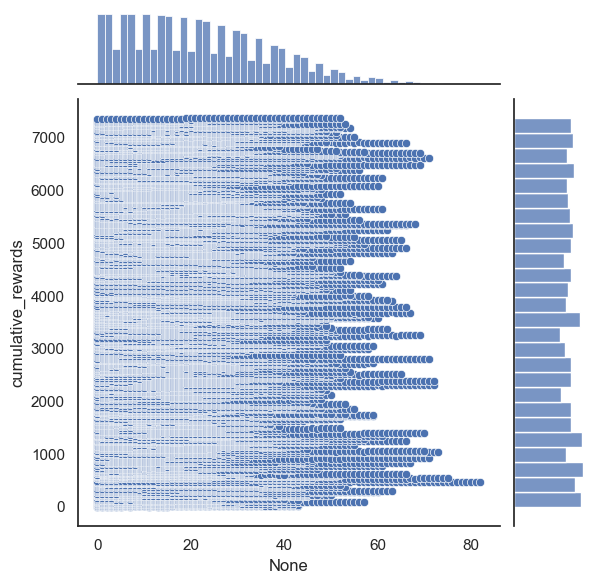

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculating the cumulative rewards if not already present
data['cumulative_rewards'] = data['rewards'].cumsum()

# Creating the joint plot
sns.set(style="white")  # Set the style of the plot
joint_plot = sns.jointplot(x=data.index, y="cumulative_rewards", data=data, kind="scatter")

# Optionally, you can add a regression line or a different kind of plot
# For example, to add a regression line, use kind="reg" instead of "scatter"

plt.show()

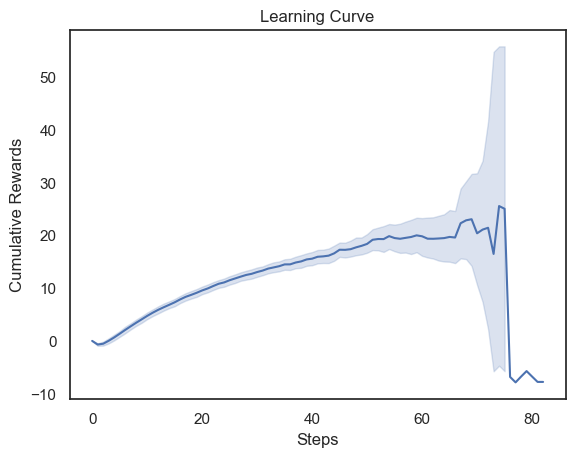

In [81]:
data['cumulative_rewards'] =  data.groupby('episodes')['rewards'].cumsum()

# Line plot
sns.lineplot(x=data.index, y='cumulative_rewards', data=data)
plt.xlabel('Steps')
plt.ylabel('Cumulative Rewards')
plt.title('Learning Curve')
plt.show()

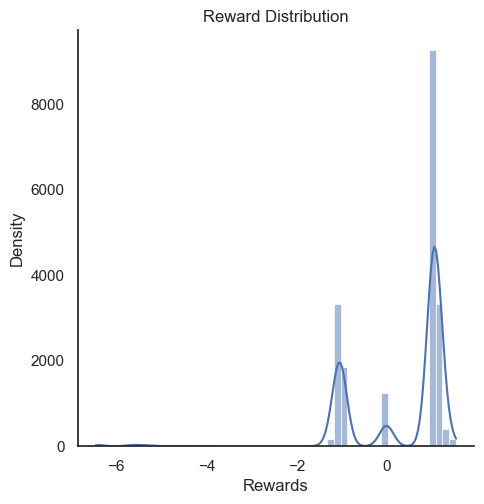

In [82]:
sns.displot(data['rewards'], kde=True)
plt.title('Reward Distribution')
plt.xlabel('Rewards')
plt.ylabel('Density')
plt.show()

In [83]:
# Ensure a unique index by resetting it
data = data.reset_index()


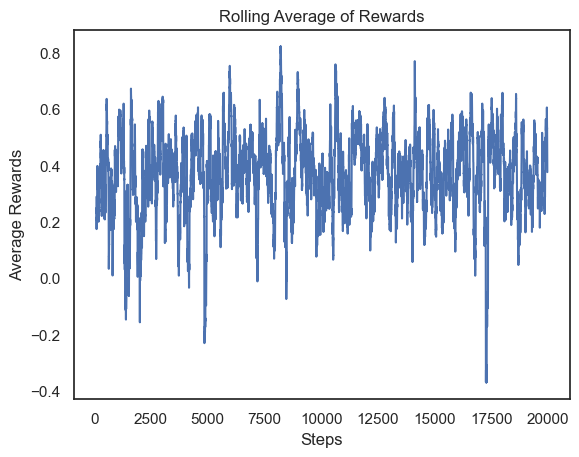

In [84]:

# Calculate the rolling average
rolling_avg_rewards = data['rewards'].rolling(window=100).mean()  # Adjust the window size as needed

# Plotting the rolling average of rewards
sns.lineplot(x=data.index, y=rolling_avg_rewards)
plt.title('Rolling Average of Rewards')
plt.xlabel('Steps')
plt.ylabel('Average Rewards')
plt.show()


In [85]:
data[["episodes", "rewards"]].to_csv("my_rewards.csv")

In [86]:
data.filter(regex="rewards")

,rewards,cum_rewards,real_cum_rewards,cumulative_rewards
0,0.000000,0.000000,NaN,0.000000
1,0.000000,0.000000,0.186140,0.000000
2,1.350104,1.350104,0.479521,1.350104
3,1.216477,2.566582,0.732233,2.566582
4,1.034703,3.601284,1.292459,3.601284
...,...,...,...,...
19964,-1.003142,11.477936,15.250917,11.477936
19965,-1.033071,10.444865,14.972277,10.444865
19966,1.013953,11.458818,15.661668,11.458818
19967,-1.005954,10.452865,15.714415,10.452865


<Axes: >

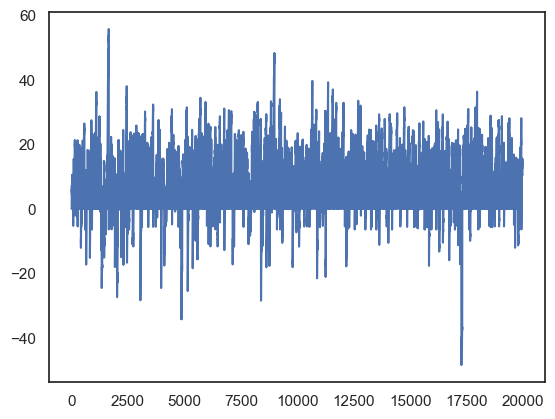

In [87]:
data.groupby("episodes")["rewards"].cumsum().plot()

episodes
2    Axes(0.125,0.11;0.775x0.77)
3    Axes(0.125,0.11;0.775x0.77)
4    Axes(0.125,0.11;0.775x0.77)
5    Axes(0.125,0.11;0.775x0.77)
6    Axes(0.125,0.11;0.775x0.77)
7    Axes(0.125,0.11;0.775x0.77)
Name: cum_rewards, dtype: object

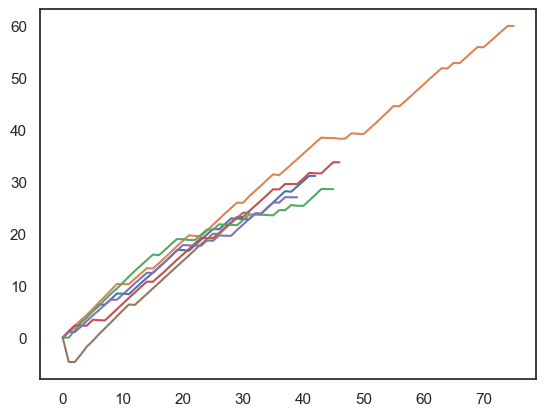

In [88]:
import pandas as pd
data = pd.read_parquet("experiment_results/results_1000000.parquet")
data["episodes"] = data["episodes"].astype(int)
data.groupby("episodes").cum_rewards.plot()

In [1]:
data.groupby("episodes").rewards.cumsum().reset_index()["rewards"].plot()

NameError: name 'data' is not defined

In [140]:
import pandas as pd
import plotly.graph_objs as go

def smooth_and_plot_rewards(rewards_series, window_size=10):
    """
    Smooths the cumulative rewards using a rolling window and plots the original and smoothed rewards.

    :param rewards_series: Pandas Series containing cumulative rewards.
    :param window_size: Size of the rolling window for smoothing.
    """
    # Calculate the rolling mean for smoothing
    smoothed_rewards = rewards_series.rolling(window=window_size, min_periods=1).mean()

    # Create the original rewards trace
    original_trace = go.Scatter(
        y=rewards_series,
        mode='lines',
        name='Original Rewards'
    )

    # Create the smoothed rewards trace
    smoothed_trace = go.Scatter(
        y=smoothed_rewards,
        mode='lines',
        name=f'Smoothed Rewards (window={window_size})'
    )

    # Layout settings
    layout = go.Layout(
        title='Cumulative Rewards - Original vs. Smoothed',
        xaxis=dict(title='Episodes'),
        yaxis=dict(title='Cumulative Reward'),
        hovermode='closest'
    )

    # Create the figure and add traces
    fig = go.Figure(data=[original_trace, smoothed_trace], layout=layout)

    # Show the plot
    fig.show()

# Example usage
# Assuming you have a Pandas Series 'cum_rewards_series'
smooth_and_plot_rewards(cum_rewards_series, window_size=10)


NameError: name 'cum_rewards_series' is not defined

In [145]:
data.query("budget == 1000000 and experiment=='dqn'").decision.value_counts()

decision
0    260
Name: count, dtype: int64

In [143]:
smooth_and_plot_rewards(data.query("budget == 1000000 and experiment=='dqn'").rewards)

In [137]:
import pandas as pd
import plotly.graph_objs as go

def smooth_and_plot_rewards_by_experiment_budget(df, window_size=10, max_episodes =10):
    """
    Smooths the cumulative rewards using a rolling window and plots the original and smoothed rewards
    for each experiment and budget.

    :param df: DataFrame containing 'experiment', 'initial_budget', 'episode', and 'cumulative_reward'.
    :param window_size: Size of the rolling window for smoothing.
    """
    # Iterating through each combination of experiment and budget
    for (experiment, budget), group_df in df.groupby(['experiment', 'initial_budget']):
        df = df.query(f'episodes<{max_episodes}')
        
        df['cum_rewards'] = df.pivot_table("episodes", "experiment", "initial_budget")['rewards'].cumsum()

        # Isolate the cumulative rewards for the current group
        rewards_series = group_df.sort_values(by='episodes')['cum_rewards']

        # Calculate the rolling mean for smoothing
        smoothed_rewards = rewards_series.rolling(window=window_size, min_periods=1).mean()

        # Create the original rewards trace
        original_trace = go.Scatter(
            y=rewards_series,
            mode='lines',
            name=f'Original Rewards - {experiment}, Budget {budget}'
        )

        # Create the smoothed rewards trace
        smoothed_trace = go.Scatter(
            y=smoothed_rewards,
            mode='lines',
            name=f'Smoothed Rewards (window={window_size}) - {experiment}, Budget {budget}'
        )

        # Layout settings
        layout = go.Layout(
            title=f'Cumulative Rewards - Original vs. Smoothed ({experiment}, Budget {budget})',
            xaxis=dict(title='Episodes'),
            yaxis=dict(title='Cumulative Reward'),
            hovermode='closest'
        )

        # Create the figure and add traces
        fig = go.Figure(data=[original_trace, smoothed_trace], layout=layout)

        # Show the plot
        fig.show()


In [138]:
smooth_and_plot_rewards_by_experiment_budget(data, 100)

KeyError: 'rewards'